# Experiment 2: OOD uncertainty analysis

This notebook analyses the synthetic one-dimensional regression experiment and the Combined Cycle Power Plant experiment. It displays the synthetic prediction figures and compares RMSE, NLL, CRPS, and 90% interval coverage between in-distribution (ID) and out-of-distribution (OOD) observations.

In [ ]:
from pathlib import Path

import matplotlib.image as mpimg
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from IPython.display import display
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler

sns.set_theme(style="whitegrid", context="notebook")
pd.set_option("display.max_columns", None)
pd.set_option("display.precision", 4)

PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
RESULT_PATH = PROJECT_ROOT / "results" / "tables" / "experiment_2.csv"
FIGURE_DIRECTORY = PROJECT_ROOT / "results" / "figures" / "experiment_2"

if not RESULT_PATH.exists():
    raise FileNotFoundError(
        f"{RESULT_PATH} does not exist. Run `.venv/bin/python -u "
        "experiments/experiment_2.py` from the project root first."
    )

results = pd.read_csv(RESULT_PATH)
METRICS = ["mean_predictive_std", "rmse", "nll", "crps", "coverage_90"]
required_columns = {"dataset", "split", "model", "evaluation_region", *METRICS}
missing = required_columns.difference(results.columns)
if missing:
    raise ValueError(f"Missing required result columns: {sorted(missing)}")

dataset_labels = {
    "synthetic_ood": "Synthetic 1D",
    "power_plant_ood": "Power Plant",
}
preferred_model_order = [
    "exact_gp", "sparse_gp_m16", "sparse_gp_m64",
    "sparse_gp_m256", "deep_ensemble", "mc_dropout",
    "mc_dropout_standard", "dkl",
]
available_models = results["model"].dropna().astype(str).unique().tolist()
model_order = [model for model in preferred_model_order if model in available_models]
model_order += sorted(set(available_models).difference(model_order))
region_order = ["id", "ood"]
results["dataset_label"] = results["dataset"].map(dataset_labels).fillna(results["dataset"])
results["model"] = pd.Categorical(results["model"], model_order, ordered=True)
results["evaluation_region"] = pd.Categorical(
    results["evaluation_region"], region_order, ordered=True
)
print(f"Loaded {len(results):,} regional result rows from {RESULT_PATH}")
display(results.head())

Loaded 600 regional result rows from /Users/paulbahde/Desktop/UncertaintyQuantification/results/tables/experiment_2_new2.csv


,dataset,split,train_size,objective_train_size,validation_size,selected_epoch,optimization_epochs,optimization_steps,optimization_status,n_inducing,final_training_time_seconds,model,inference_time_seconds,evaluation_region,n_evaluation,mean_predictive_std,rmse,nll,crps,coverage_90,dataset_label
0,synthetic_ood,0,100,100,0,59.0,64.0,64.0,converged,NaN,1.3611,exact_gp,0.0039,id,300,0.2029,0.2082,-0.1504,0.1168,0.9167,Synthetic 1D
1,synthetic_ood,0,100,100,0,59.0,64.0,64.0,converged,NaN,1.3611,exact_gp,0.0039,ood,200,0.6318,0.4502,0.6435,0.2587,0.9900,Synthetic 1D
2,synthetic_ood,0,100,100,0,50.0,55.0,220.0,converged,16.0,1.0155,sparse_gp_m16,0.0023,id,300,0.2753,0.2154,-0.0652,0.1232,0.9700,Synthetic 1D
3,synthetic_ood,0,100,100,0,50.0,55.0,220.0,converged,16.0,1.0155,sparse_gp_m16,0.0023,ood,200,0.5918,0.4847,0.6845,0.2766,0.9900,Synthetic 1D
4,synthetic_ood,0,100,100,0,50.0,55.0,220.0,converged,64.0,1.3214,sparse_gp_m64,0.0027,id,300,0.2745,0.2354,-0.0125,0.1325,0.9467,Synthetic 1D


## 1. PCA direction used for the Power Plant ID/OOD split

The Power Plant split standardizes all four input features before fitting PCA, exactly as in `experiments/experiment_2.py`. The first principal component (PC1) explains **60.96%** of the total standardized input variance. In absolute terms it is dominated by **ambient temperature (AT; loading 0.615, squared-loading share 37.80%)** and **exhaust vacuum (V; 0.560, 31.32%)**. Ambient pressure (AP; -0.404, 16.34%) and relative humidity (RH; -0.381, 14.54%) contribute less. Thus, the tail-based OOD split is primarily a joint temperature/vacuum direction, with pressure and humidity varying in the opposite direction.

PCA component signs are arbitrary: multiplying every loading and every PC1 score by -1 describes the same split. Therefore, component dominance should be interpreted through absolute or squared loadings.

Variance explained by PC1: 60.96%


,feature,description,loading,absolute_loading,squared_loading_share
0,AT,Ambient temperature,+0.6148,0.6148,37.80%
1,V,Exhaust vacuum,+0.5597,0.5597,31.32%
2,AP,Ambient pressure,-0.4042,0.4042,16.34%
3,RH,Relative humidity,-0.3813,0.3813,14.54%


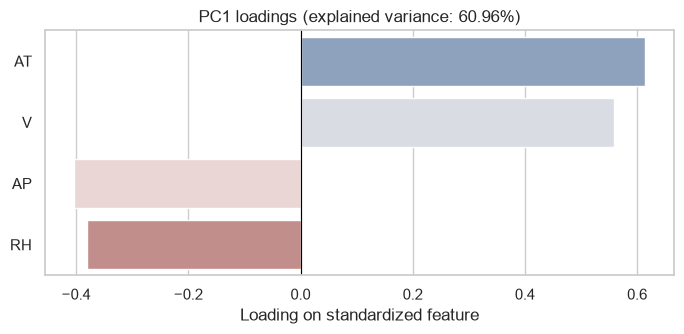

In [2]:
power_plant_cache = PROJECT_ROOT / ".cache" / "uci" / "power_plant_294.npz"
if not power_plant_cache.exists():
    raise FileNotFoundError(
        f"{power_plant_cache} does not exist. Load the Power Plant dataset first."
    )

with np.load(power_plant_cache) as cached:
    X_power_plant = cached["X"]

feature_names = ["AT", "V", "AP", "RH"]
feature_descriptions = [
    "Ambient temperature",
    "Exhaust vacuum",
    "Ambient pressure",
    "Relative humidity",
]
if X_power_plant.shape[1] != len(feature_names):
    raise ValueError("Unexpected number of Power Plant input features")

X_standardized = StandardScaler().fit_transform(X_power_plant)
pca = PCA().fit(X_standardized)
pc1_loadings = pca.components_[0]
loading_table = (
    pd.DataFrame(
        {
            "feature": feature_names,
            "description": feature_descriptions,
            "loading": pc1_loadings,
            "absolute_loading": np.abs(pc1_loadings),
            "squared_loading_share": pc1_loadings**2,
        }
    )
    .sort_values("absolute_loading", ascending=False)
    .reset_index(drop=True)
)

print(f"Variance explained by PC1: {pca.explained_variance_ratio_[0]:.2%}")
display(
    loading_table.style.format(
        {
            "loading": "{:+.4f}",
            "absolute_loading": "{:.4f}",
            "squared_loading_share": "{:.2%}",
        }
    )
)

fig, axis = plt.subplots(figsize=(7, 3.5))
sns.barplot(
    data=loading_table, x="loading", y="feature",
    hue="feature", palette="vlag", legend=False, ax=axis,
)
axis.axvline(0, color="black", linewidth=0.8)
axis.set(
    title=f"PC1 loadings (explained variance: {pca.explained_variance_ratio_[0]:.2%})",
    xlabel="Loading on standardized feature", ylabel="",
)
fig.tight_layout()
plt.show()

## 2. Synthetic one-dimensional prediction figures

Each available model has a panel showing its predictive mean and nominal 90% prediction interval together with the true function and fitting observations. The interval visualizes the model's reported predictive uncertainty, and the shaded outer ranges are OOD.

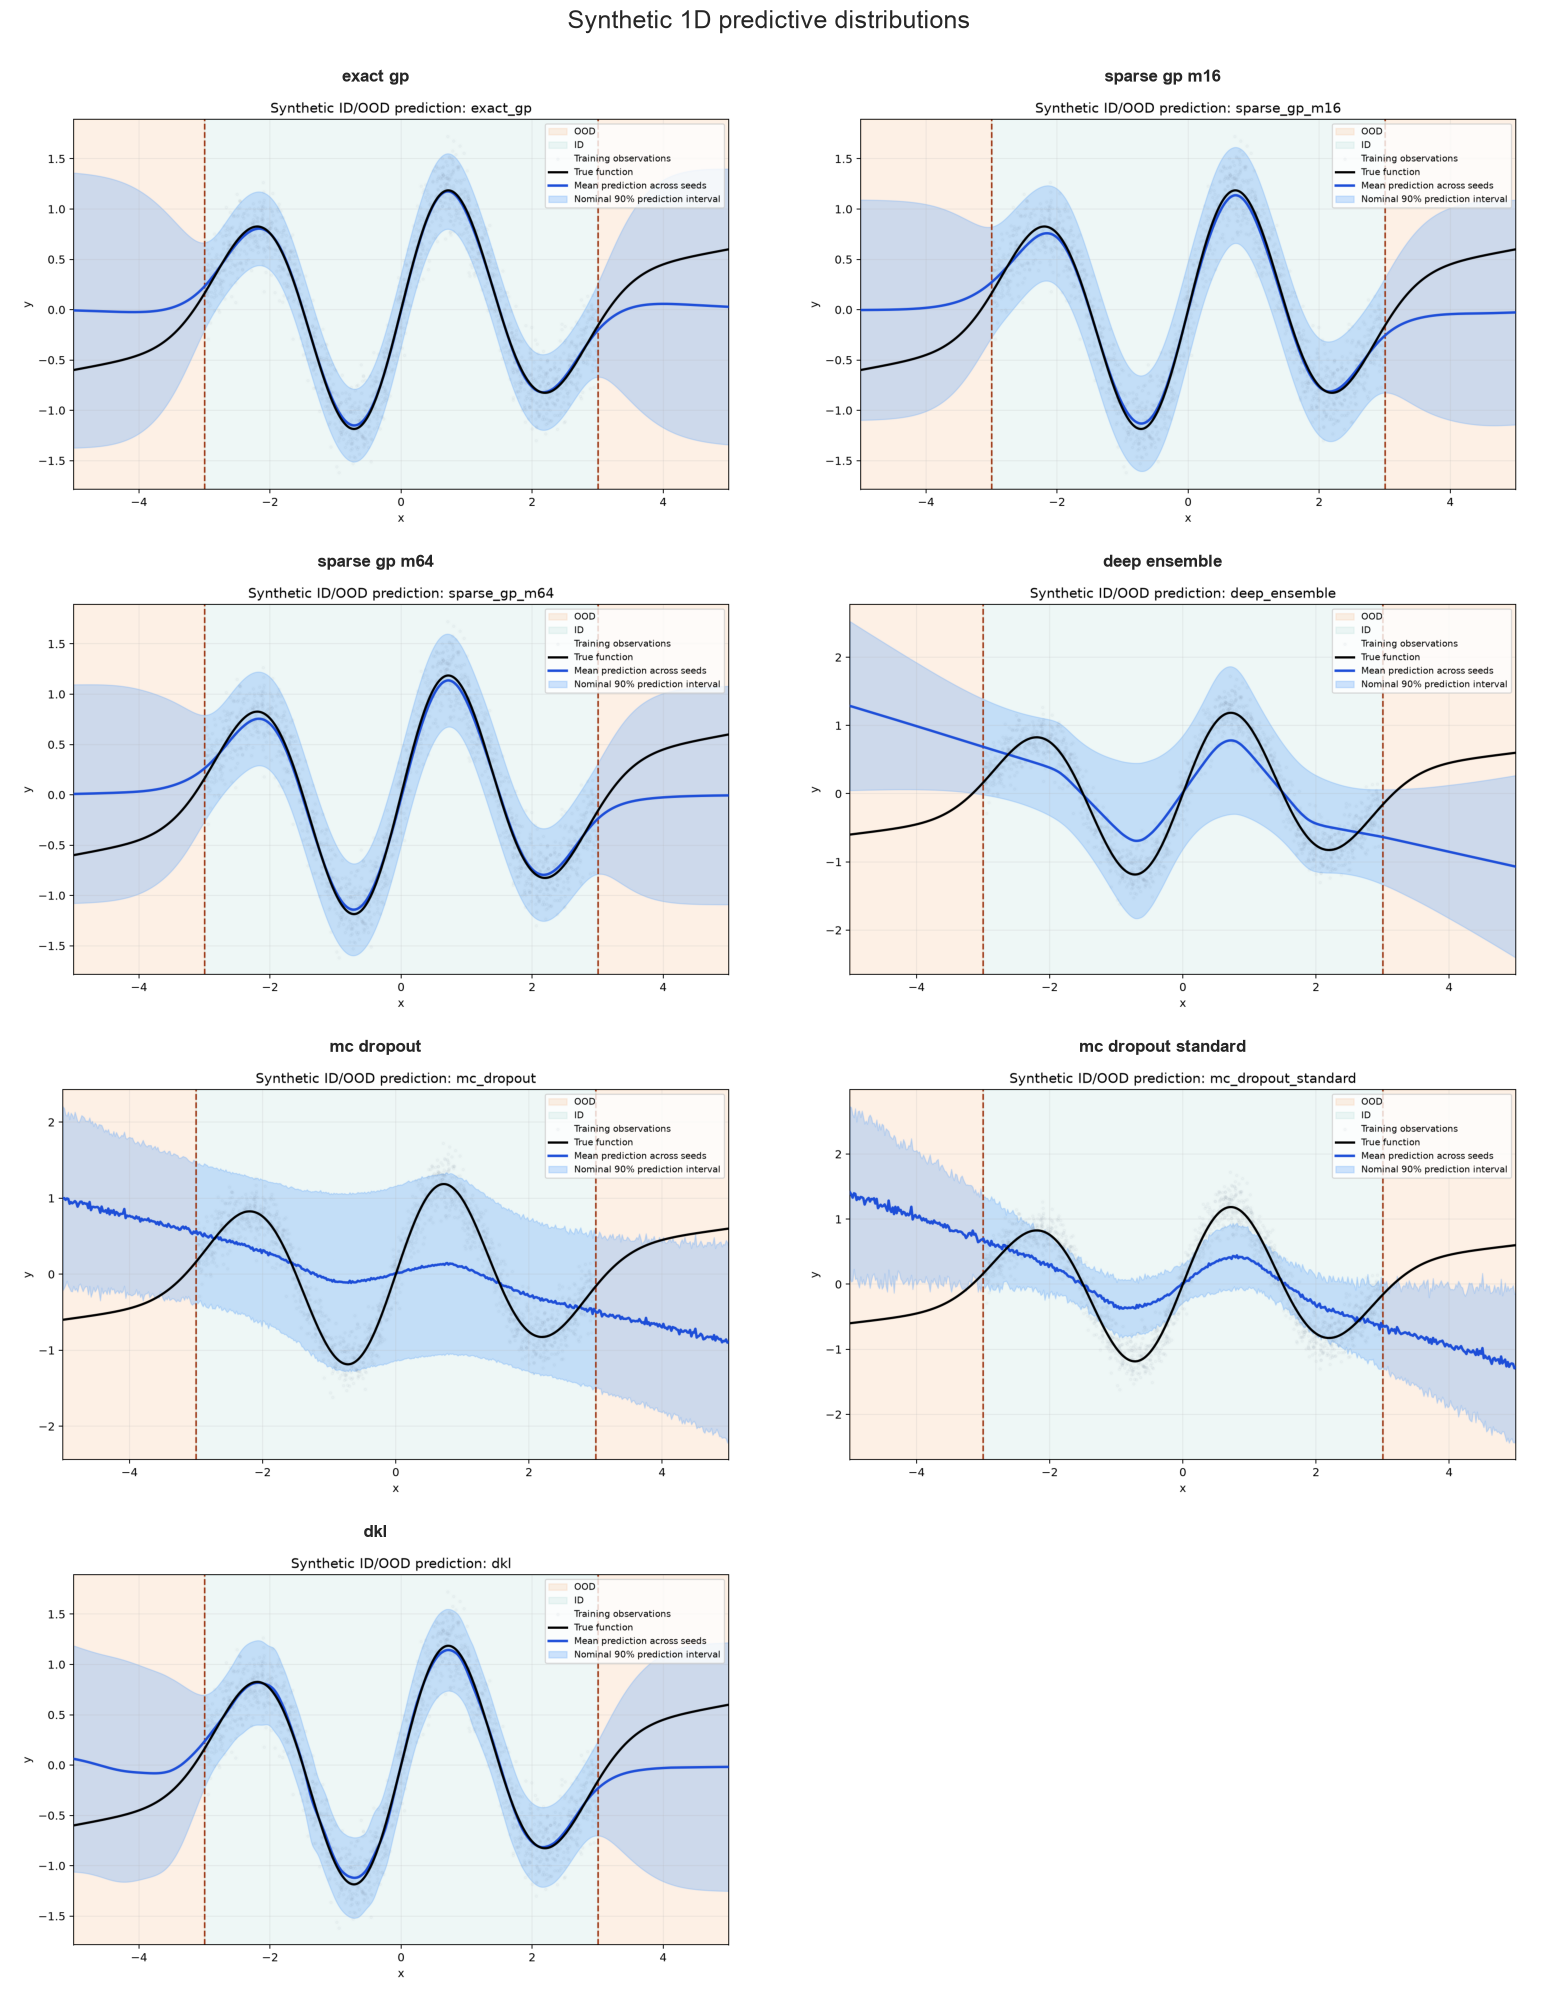

In [3]:
synthetic_models = results.loc[
    results["dataset"] == "synthetic_ood", "model"
].dropna().astype(str).unique()
figure_models = [model for model in model_order if model in synthetic_models]
figure_paths = [FIGURE_DIRECTORY / f"{model}.png" for model in figure_models]
missing_figures = [path for path in figure_paths if not path.exists()]
if missing_figures:
    raise FileNotFoundError(
        "Missing synthetic prediction figures: "
        + ", ".join(path.name for path in missing_figures)
        + ". Run Experiment 2 before executing this notebook."
    )

n_columns = 2
n_rows = int(np.ceil(len(figure_models) / n_columns))
fig, axes = plt.subplots(n_rows, n_columns, figsize=(16, 5 * n_rows), squeeze=False)
for axis, path, model in zip(axes.flat, figure_paths, figure_models):
    axis.imshow(mpimg.imread(path))
    axis.set_title(model.replace("_", " "), fontweight="bold")
    axis.axis("off")
for axis in axes.flat[len(figure_paths):]:
    axis.axis("off")
fig.suptitle("Synthetic 1D predictive distributions", fontsize=18, y=1.0)
fig.tight_layout()
plt.show()

## 3. Metrics aggregated over seeds

The table reports mean ± sample standard deviation across the 20 seeds. ID and OOD remain separate throughout. Mean predictive standard deviation directly reports the models' predictive uncertainty. Lower is better for RMSE, NLL, and CRPS; coverage is best interpreted relative to the nominal value of 0.90.

In [4]:
summary = (
    results.groupby(
        ["dataset_label", "model", "evaluation_region"],
        observed=True,
    )
    .agg(
        seeds=("split", "nunique"),
        **{
            f"{metric}_{stat}": (metric, stat)
            for metric in METRICS
            for stat in ("mean", "std")
        },
    )
    .reset_index()
    .sort_values(["dataset_label", "model", "evaluation_region"])
)

formatted_summary = summary[["dataset_label", "model", "evaluation_region", "seeds"]].copy()
for metric in METRICS:
    formatted_summary[metric] = summary.apply(
        lambda row: f"{row[f'{metric}_mean']:.4f} ± {row[f'{metric}_std']:.4f}",
        axis=1,
    )
display(formatted_summary)

,dataset_label,model,evaluation_region,seeds,mean_predictive_std,rmse,nll,crps,coverage_90
0,Power Plant,exact_gp,id,20,4.0487 ± 0.2577,4.1062 ± 0.0563,2.8338 ± 0.0129,2.2550 ± 0.0355,0.9109 ± 0.0171
1,Power Plant,exact_gp,ood,20,4.6029 ± 0.2471,5.2320 ± 0.6034,3.0919 ± 0.1143,2.8872 ± 0.3486,0.8726 ± 0.0296
2,Power Plant,sparse_gp_m16,id,20,4.4117 ± 0.2425,4.2028 ± 0.0654,2.8588 ± 0.0155,2.3199 ± 0.0397,0.9275 ± 0.0135
3,Power Plant,sparse_gp_m16,ood,20,4.7532 ± 0.2364,5.2126 ± 0.4310,3.0765 ± 0.0948,2.8935 ± 0.2737,0.8859 ± 0.0393
4,Power Plant,sparse_gp_m64,id,20,4.3104 ± 0.2606,4.1632 ± 0.0570,2.8484 ± 0.0134,2.2943 ± 0.0347,0.9239 ± 0.0158
5,Power Plant,sparse_gp_m64,ood,20,4.6932 ± 0.2580,5.4120 ± 0.5101,3.1184 ± 0.1039,3.0118 ± 0.3208,0.8617 ± 0.0370
6,Power Plant,sparse_gp_m256,id,20,4.2963 ± 0.2708,4.1645 ± 0.0636,2.8482 ± 0.0161,2.2935 ± 0.0400,0.9225 ± 0.0160
7,Power Plant,sparse_gp_m256,ood,20,4.7172 ± 0.2566,5.4278 ± 0.4920,3.1195 ± 0.1019,3.0174 ± 0.3091,0.8641 ± 0.0379
8,Power Plant,deep_ensemble,id,20,3.8857 ± 0.1932,4.1022 ± 0.0430,2.8481 ± 0.0162,2.2562 ± 0.0222,0.8955 ± 0.0126
9,Power Plant,deep_ensemble,ood,20,3.7282 ± 0.4617,4.9568 ± 0.1403,3.1899 ± 0.1131,2.7917 ± 0.0999,0.7957 ± 0.0478


## 4. Side-by-side ID and OOD comparison

Each metric uses one shared figure for both datasets. Within every model, the ID and OOD bars are adjacent. Error bars show one standard deviation across seeds, and the dashed coverage reference marks the nominal 90% target.

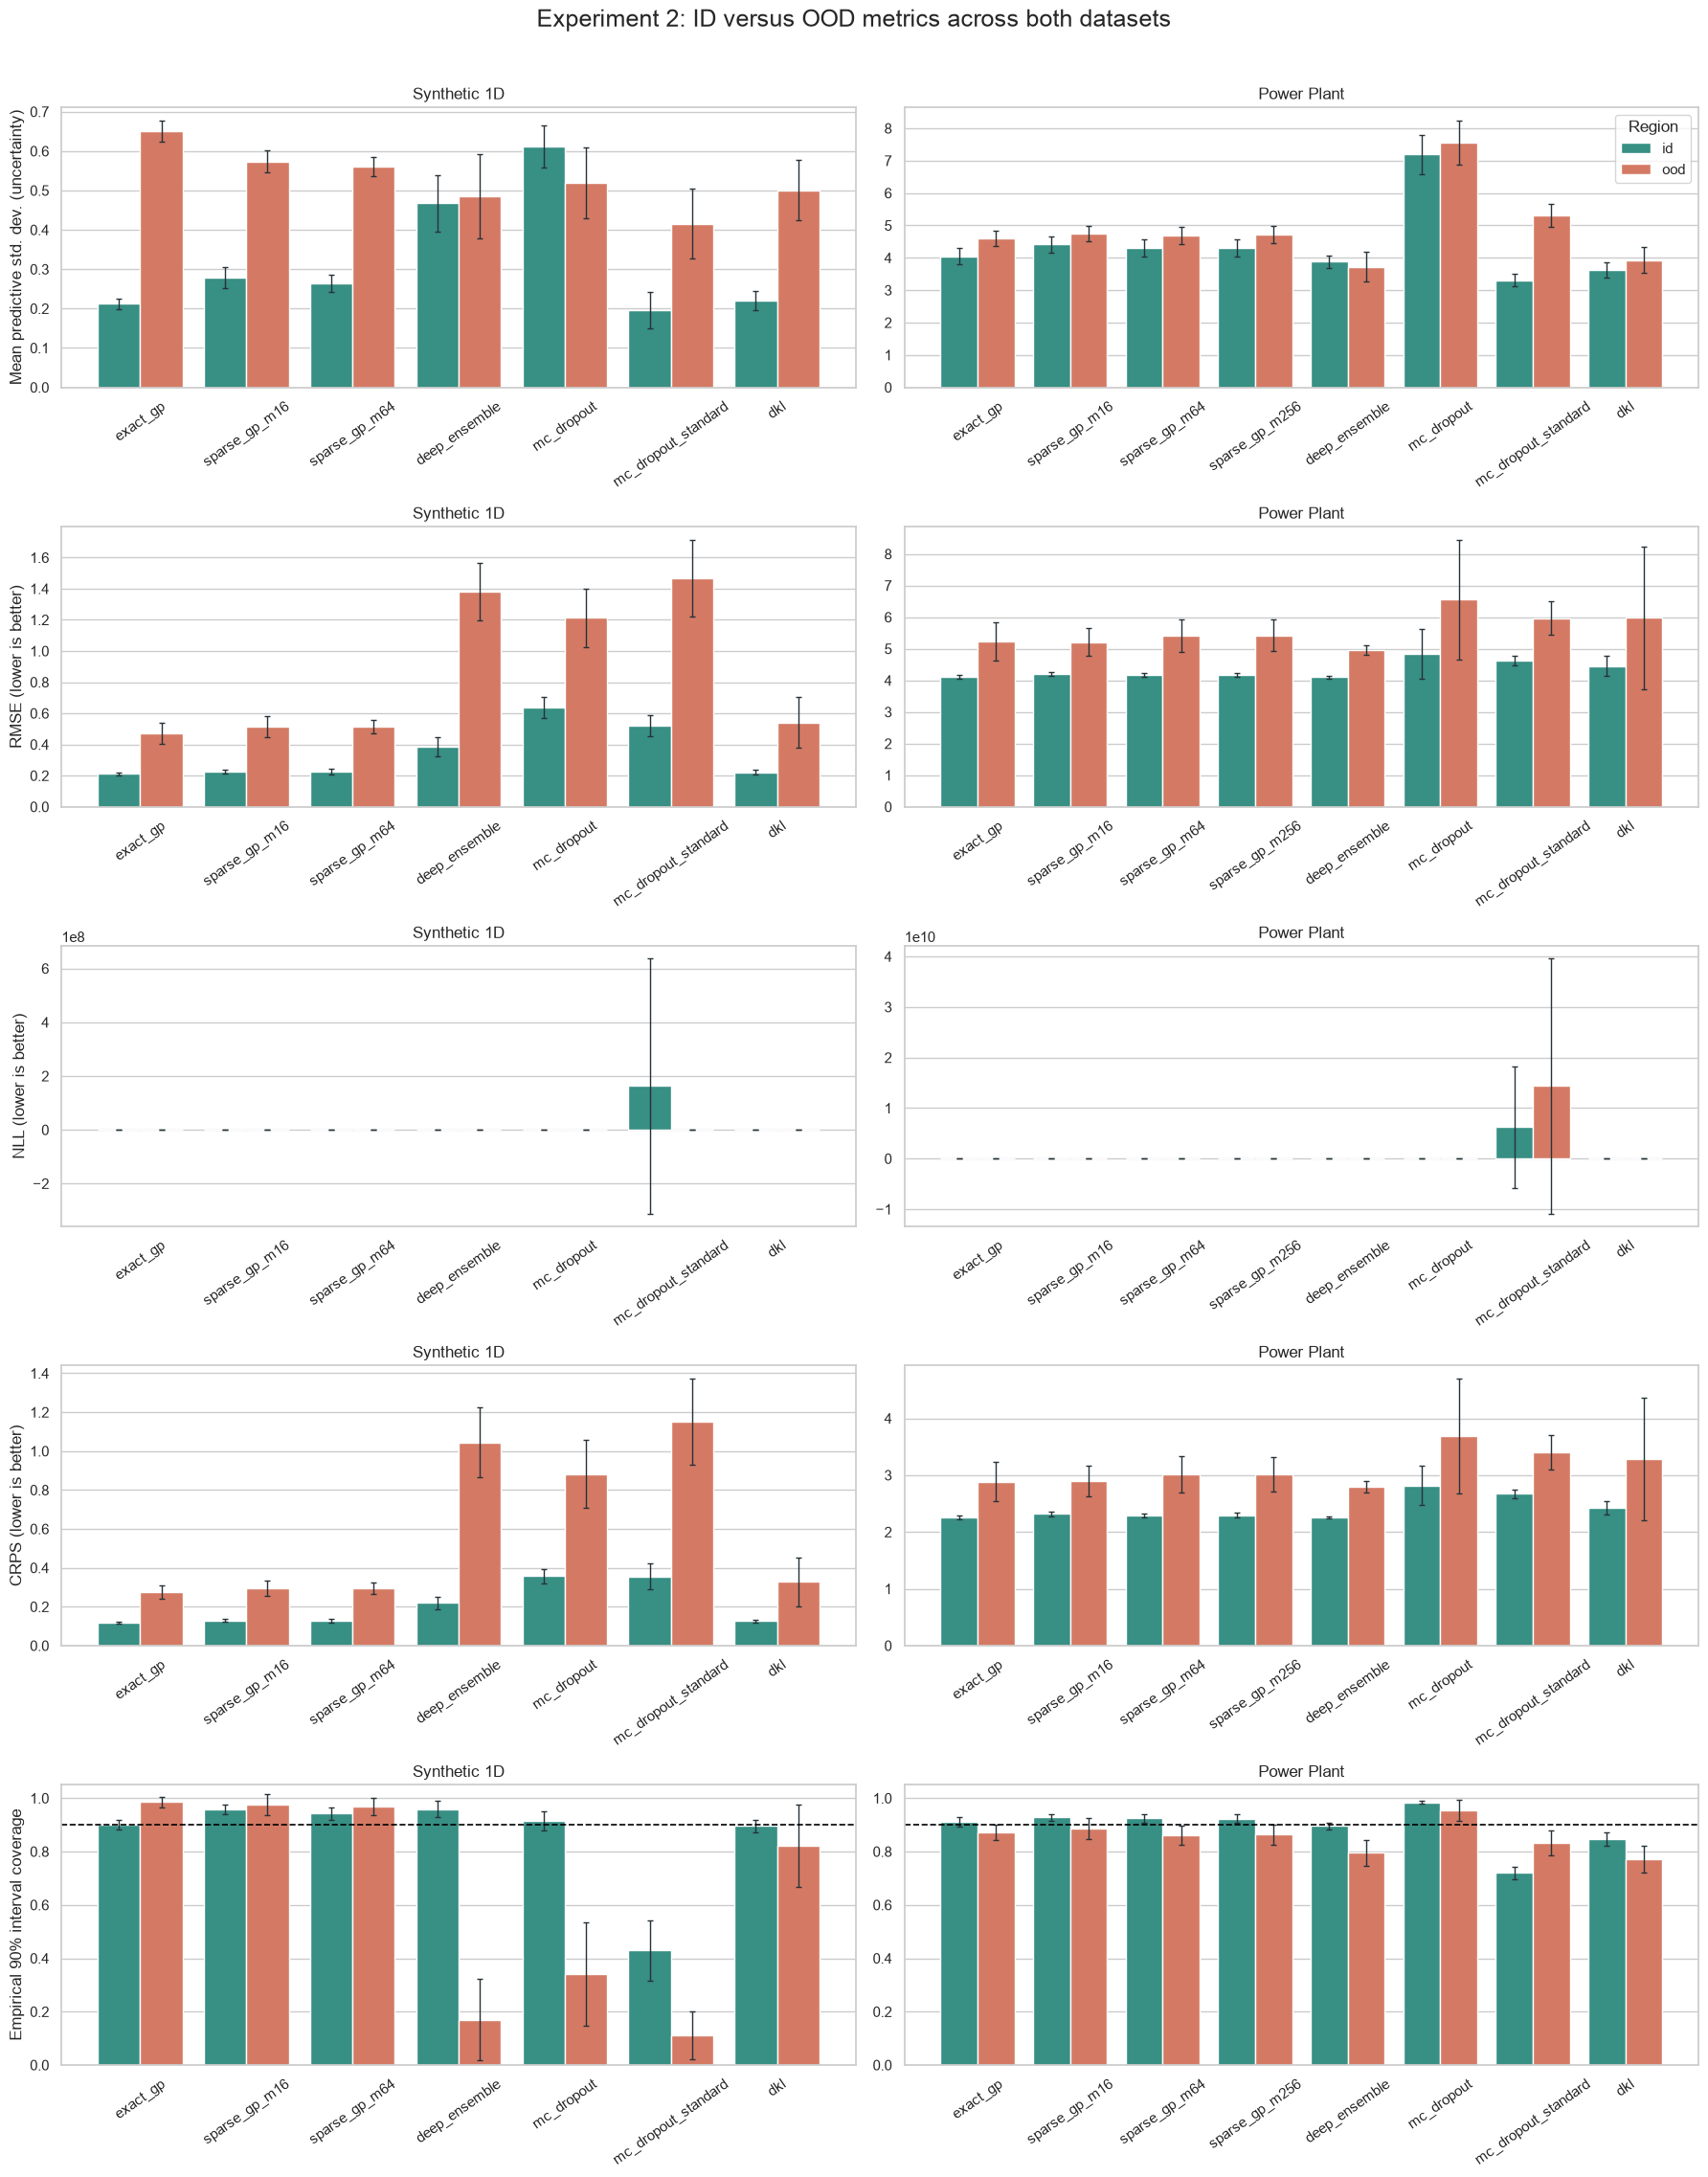

In [5]:
metric_labels = {
    "mean_predictive_std": "Mean predictive std. dev. (uncertainty)",
    "rmse": "RMSE (lower is better)",
    "nll": "NLL (lower is better)",
    "crps": "CRPS (lower is better)",
    "coverage_90": "Empirical 90% interval coverage",
}
palette = {"id": "#2a9d8f", "ood": "#e76f51"}
dataset_order = [label for label in dataset_labels.values() if label in summary["dataset_label"].unique()]

fig, axes = plt.subplots(
    len(METRICS), len(dataset_order),
    figsize=(18, 4.5 * len(METRICS)),
    squeeze=False,
)

for row_index, metric in enumerate(METRICS):
    for column_index, dataset_label in enumerate(dataset_order):
        axis = axes[row_index, column_index]
        plot_data = summary[summary["dataset_label"] == dataset_label]
        dataset_model_order = [
            model for model in model_order if model in plot_data["model"].astype(str).unique()
        ]
        sns.barplot(
            data=plot_data, x="model", y=f"{metric}_mean",
            hue="evaluation_region", order=dataset_model_order, hue_order=region_order,
            palette=palette, errorbar=None, ax=axis,
        )

        # Add the across-seed standard deviations to the grouped bars.
        containers = axis.containers[:len(region_order)]
        for region, container in zip(region_order, containers):
            region_data = (
                plot_data[plot_data["evaluation_region"] == region]
                .set_index("model")
                .reindex(dataset_model_order)
            )
            for bar, std in zip(container, region_data[f"{metric}_std"]):
                if np.isfinite(std):
                    axis.errorbar(
                        bar.get_x() + bar.get_width() / 2, bar.get_height(),
                        yerr=std, color="#263238", capsize=2, linewidth=1,
                    )

        if metric == "coverage_90":
            axis.axhline(0.90, color="black", linestyle="--", linewidth=1.2, label="Nominal 0.90")
            axis.set_ylim(0, 1.05)
        axis.set_title(dataset_label)
        axis.set_xlabel("")
        axis.set_ylabel(metric_labels[metric] if column_index == 0 else "")
        axis.tick_params(axis="x", rotation=35)
        if not (row_index == 0 and column_index == len(dataset_order) - 1):
            legend = axis.get_legend()
            if legend is not None:
                legend.remove()
        else:
            axis.legend(title="Region")

fig.suptitle("Experiment 2: ID versus OOD metrics across both datasets", fontsize=18, y=1.01)
fig.tight_layout()
plt.show()

## 5. OOD change relative to ID

This compact table subtracts each model's mean ID score from its mean OOD score. A positive mean-predictive-standard-deviation change means reported uncertainty increased OOD. Positive RMSE, NLL, or CRPS changes indicate degradation outside the training distribution. For coverage, a negative change means that coverage fell in the OOD region.

In [6]:
mean_columns = [f"{metric}_mean" for metric in METRICS]
wide = summary.pivot(
    index=["dataset_label", "model"],
    columns="evaluation_region",
    values=mean_columns,
)
ood_change = pd.DataFrame(
    {
        metric: wide[(f"{metric}_mean", "ood")] - wide[(f"{metric}_mean", "id")]
        for metric in METRICS
    }
).reset_index()
display(ood_change.style.format({metric: "{:+.4f}" for metric in METRICS}))

,dataset_label,model,mean_predictive_std,rmse,nll,crps,coverage_90
0,Power Plant,exact_gp,+0.5541,+1.1258,+0.2580,+0.6322,-0.0382
1,Power Plant,sparse_gp_m16,+0.3416,+1.0099,+0.2177,+0.5735,-0.0417
2,Power Plant,sparse_gp_m64,+0.3828,+1.2487,+0.2701,+0.7175,-0.0622
3,Power Plant,sparse_gp_m256,+0.4209,+1.2633,+0.2713,+0.7240,-0.0584
4,Power Plant,deep_ensemble,-0.1575,+0.8546,+0.3418,+0.5356,-0.0997
5,Power Plant,mc_dropout,+0.3607,+1.7152,+0.1851,+0.8737,-0.0306
6,Power Plant,mc_dropout_standard,+2.0107,+1.3398,+8115596587.1755,+0.7250,+0.1125
7,Power Plant,dkl,+0.3138,+1.5237,+0.4260,+0.8584,-0.0768
8,Synthetic 1D,exact_gp,+0.4390,+0.2588,+0.8459,+0.1555,+0.0843
9,Synthetic 1D,sparse_gp_m16,+0.2950,+0.2908,+0.7648,+0.1673,+0.0187
